# 05 — End-to-End Lorenz-63 Pipeline

This notebook demonstrates the full data-preprocessing and training pipeline
for 4DVarNet on the Lorenz-63 attractor, using the functional utilities in
`vardax._src.utils`.

**Pipeline overview:**
1. Simulate L63 with Diffrax
2. Build an xarray Dataset and extract patches
3. Add observation masks and Gaussian noise
4. Train/test split in time (before patch extraction)
5. Standardize
6. Convert to `Batch1D`
7. Visualize raw data
8. Train `FourDVarNet1D`
9. Evaluate and visualize reconstruction

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import vardax
from vardax import Batch1D, FourDVarNet1D
from vardax._src.utils.dynamical_systems import simulate_lorenz63
from vardax._src.utils.patches import trajectory_to_xr_dataset, extract_patches
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.preprocessing import xr_to_batch1d
from vardax._src.utils.standardize import (
    compute_scaler_params,
    apply_standardization,
    inverse_standardization,
)
from vardax._src.utils.viz import (
    plot_3d_attractor,
    plot_state_grid,
    plot_trajectories,
    plot_reconstruction_comparison,
)

## 1. Simulate Lorenz-63

In [2]:
key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(
    key,
    sigma=10.0,
    rho=28.0,
    beta=8.0 / 3.0,
    dt=0.01,
    n_steps=5000,
    n_burn_in=1000,
)
print(f"states shape: {states.shape}, time range: [{time_coords[0]:.2f}, {time_coords[-1]:.2f}]")

states shape: (5001, 3), time range: [0.00, 50.00]


## 2. Build xarray Dataset and Extract Patches

In [3]:
ds = trajectory_to_xr_dataset(states, time_coords, feature_names=["X", "Y", "Z"])
print(ds)

<xarray.Dataset> Size: 80kB
Dimensions:  (time: 5001, feature: 3)
Coordinates:
  * time     (time) float32 20kB 0.0 0.01 0.02 0.03 ... 49.97 49.98 49.99 50.0
  * feature  (feature) <U1 12B 'X' 'Y' 'Z'
Data variables:
    state    (time, feature) float32 60kB -4.885 -3.767 24.61 ... -1.112 17.2


## 3. Train/Test Split in Time, Then Extract Patches

The trajectory is split in time *before* cutting windows, so no window
straddles the boundary. Windows drawn at random from one trajectory and
split afterwards would leak test timesteps into the training set.

In [4]:
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=160, n_timesteps=20, seed=42)
ds_test = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=40, n_timesteps=20, seed=43)
print(f"train patches: {ds_train.sizes['patch']}, test patches: {ds_test.sizes['patch']}")

train patches: 160, test patches: 40


## 4. Add Observation Masks and Gaussian Noise

In [5]:
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_test = regular_mask(ds_test, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_test = add_gaussian_noise(ds_test, variable="state", sigma=0.5, seed=1, name="obs")
print(ds_train)

<xarray.Dataset> Size: 117kB
Dimensions:  (patch: 160, time: 20, feature: 3)
Coordinates:
  * patch    (patch) int64 1kB 0 1 2 3 4 5 6 7 ... 153 154 155 156 157 158 159
  * time     (time) int64 160B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19
  * feature  (feature) <U1 12B 'X' 'Y' 'Z'
Data variables:
    state    (patch, time, feature) float32 38kB 0.005621 0.5456 ... 23.99
    mask     (patch, time, feature) float32 38kB 1.0 1.0 1.0 0.0 ... 0.0 0.0 0.0
    obs      (patch, time, feature) float32 38kB 0.06849 0.4795 ... 24.54


## 5. Standardize

In [6]:
mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
print(f"mean={mean:.4f}, std={std:.4f}")

ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_test = apply_standardization(ds_test, variables=["state", "obs"], mean=mean, std=std)

mean=7.9860, std=13.7293


## 6. Convert to Batch1D

In [7]:
batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_test = xr_to_batch1d(ds_test, state_var="state", obs_var="obs", mask_var="mask")
print(f"train: input={batch_train.input.shape}, mask={batch_train.mask.shape}, target={batch_train.target.shape}")

train: input=(160, 20, 3), mask=(160, 20, 3), target=(160, 20, 3)


## 7. Visualize Raw Data

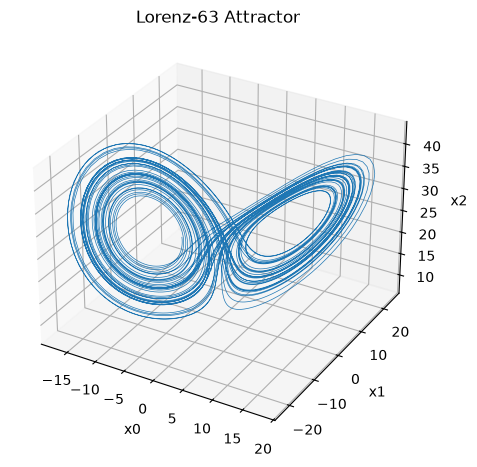

In [8]:
fig, ax = plot_3d_attractor(states)
ax.set_title("Lorenz-63 Attractor")
plt.tight_layout()
plt.show()

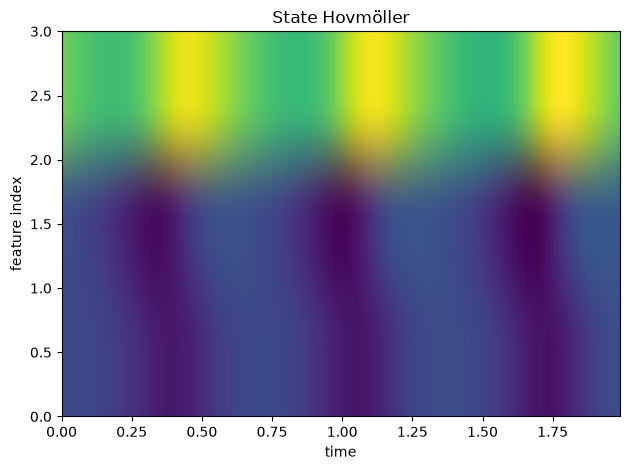

In [9]:
fig, ax = plot_state_grid(states[:200], time_coords[:200])
ax.set_title("State Hovmöller")
plt.tight_layout()
plt.show()

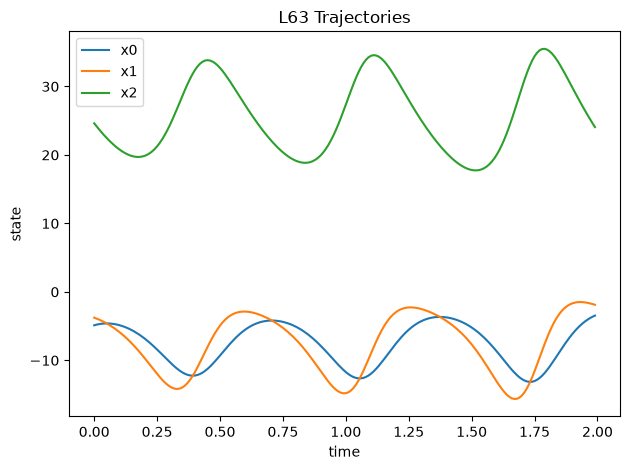

In [10]:
fig, ax = plot_trajectories(states[:200], time_coords[:200])
ax.set_title("L63 Trajectories")
plt.tight_layout()
plt.show()

## 8. Train FourDVarNet1D

In [11]:
# (NNX removed in Epic 0 — vardax is now equinox-native)

N = batch_train.input.shape[-1]   # 3 (X, Y, Z)
T = batch_train.input.shape[1]    # 20

model = FourDVarNet1D(
    state_dim=N,
    n_time=T,
    latent_dim=8,
    hidden_dim=16,
    n_solver_steps=5,
    key=jax.random.PRNGKey(1),
)

model, train_losses, _ = vardax.examples.fit_demo(
    model,
    [batch_train],
    n_epochs=5,
    lr=1e-3,
    verbose=True,
)
print("Final train loss:", train_losses[-1])

epoch 1/5 — train loss: 0.508443
epoch 2/5 — train loss: 0.493830
epoch 3/5 — train loss: 0.479898
epoch 4/5 — train loss: 0.466532
epoch 5/5 — train loss: 0.453614
Final train loss: 0.4536140561103821


## 9. Evaluate and Visualize Reconstruction

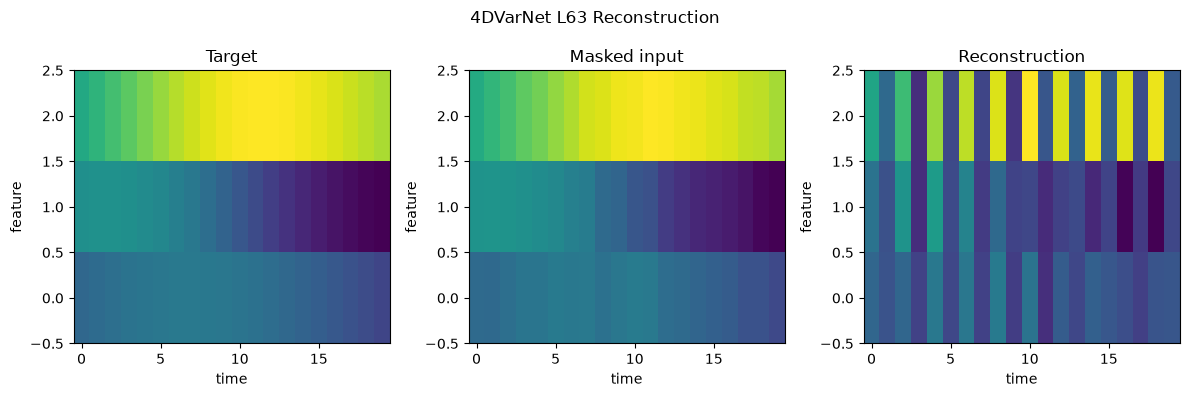

In [12]:
recon = model(batch_test)

target_np = jnp.array(batch_test.target)
input_np = jnp.array(batch_test.input)
recon_np = jnp.array(recon)

fig, axes = plot_reconstruction_comparison(target_np, input_np, recon_np, sample_idx=0)
plt.suptitle("4DVarNet L63 Reconstruction")
plt.tight_layout()
plt.show()